# CatBoost for regression

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train CatBoost to predict the rent price of an apartment. We pass the categorical variables as they are, so that CatBoost encodes them, train with early stopping, then compare ordered and plain boosting at several depths, compare the bootstrap types, and look at how the combinations of categorical variables change the model. Finally, we look at the feature importance.

CatBoost's classes, `CatBoostRegressor` and `CatBoostClassifier`, follow the scikit-learn interface, so they fit into scikit-learn pipelines and searches. They are also the full API of the library, so we use them in this course.

In [1]:
import time

import catboost as cb
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

### Load data

We use the apartment rent data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time")
df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [3]:
# CatBoost encodes the categories by itself, so we keep the strings instead of integers
cat_features = list(df.select_dtypes("str").columns)

# CatBoost rejects missing values in a categorical variable, so they become one more category
df[cat_features] = df[cat_features].fillna("missing")

# CatBoost takes missing values in the numerical variables, so we leave NaN as it is

cat_features

['category', 'fee', 'has_photo', 'pets_allowed', 'cityname', 'state', 'source']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="price"),
    df["price"],
    test_size=0.3,
    random_state=0,
)

X_train.shape, X_test.shape

((69872, 39), (29946, 39))

In [5]:
# the mean rent price
y_train.mean(), y_test.mean()

(np.float64(1527.515742929929), np.float64(1526.5632805716957))

### Prepare the data for CatBoost

CatBoost's own data container is the `Pool`, which holds the features, the target and the names of the categorical variables. We build one for the train set and one for the test set, and reuse them in the rest of the notebook.

In [6]:
train_pool = cb.Pool(X_train, y_train, cat_features=cat_features)
test_pool = cb.Pool(X_test, y_test, cat_features=cat_features)

train_pool.shape, test_pool.shape

((69872, 39), (29946, 39))

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on.

We leave out the learning rate, which CatBoost chooses from the data, and `l2_leaf_reg`: as we saw in the lectures on hyperparameters, setting it, even at its default of 3, turns off the automatic learning rate, which then falls back to 0.03. We set the number of trees, `iterations`, when we train.

In [7]:
params = {
    # learning task
    "loss_function": "RMSE",
    "eval_metric": "RMSE",           # the default follows the loss function

    # tree structure and algorithm
    "boosting_type": "Plain",        # the default on CPU; on GPU, Ordered up to 50,000 rows
    "grow_policy": "SymmetricTree",  # oblivious trees
    "has_time": False,               # random permutations, not the order of the rows
    "depth": 6,

    # categorical features
    "one_hot_max_size": 2,           # one-hot up to this many values, target statistics above
    "max_ctr_complexity": 4,         # most variables in one combination

    # sampling
    "bootstrap_type": "MVS",         # the default on CPU; Bayesian on GPU
    "subsample": 0.8,                # share of the rows for each tree, the default with MVS
    "bagging_temperature": 1,        # Bayesian only

    # feature processing
    "border_count": 254,             # the default on CPU; 128 on GPU
    "feature_border_type": "GreedyLogSum",
    "nan_mode": "Min",               # missing values go to the far left

    # hardware and reproducibility
    "task_type": "CPU",
    "thread_count": 4,               # fixed, so that the timings are comparable
    "random_seed": 0,
    "allow_writing_files": False,    # no catboost_info folder next to the notebook
}

We let CatBoost add up to 2000 trees, and with `early_stopping_rounds=50` the training stops when the rmse in the test set has not improved for 50 rounds. Here, to keep the notebook short, the test set plays the role of the validation set. In a real project, we would hold out a separate validation set, because choosing the number of trees on the test set makes the test score optimistic.

In [8]:
model = cb.CatBoostRegressor(**params, iterations=2000).fit(
    train_pool,
    eval_set=test_pool,
    early_stopping_rounds=50,
    verbose=100,
)

Learning rate set to 0.064986


0:	learn: 892.7335363	test: 844.4333052	best: 844.4333052 (0)	total: 227ms	remaining: 7m 32s


100:	learn: 509.7590510	test: 503.1593604	best: 503.1593604 (100)	total: 7.48s	remaining: 2m 20s


200:	learn: 464.9551619	test: 479.6472973	best: 479.6472973 (200)	total: 15.6s	remaining: 2m 19s


300:	learn: 436.7122271	test: 469.6721367	best: 469.6721367 (300)	total: 23.3s	remaining: 2m 11s


400:	learn: 415.1989630	test: 461.2912119	best: 461.2856691 (396)	total: 30.6s	remaining: 2m 1s


... (10 outputs left out)

1500:	learn: 322.1389720	test: 429.4064074	best: 429.3836901 (1494)	total: 1m 52s	remaining: 37.5s


1600:	learn: 318.2397237	test: 428.3547436	best: 428.3547436 (1600)	total: 2m	remaining: 30s


1700:	learn: 314.0324223	test: 427.0866266	best: 427.0866266 (1700)	total: 2m 7s	remaining: 22.5s


Stopped by overfitting detector  (50 iterations wait)

bestTest = 426.4933612
bestIteration = 1735

Shrink model to first 1736 iterations.


In [9]:
# get_best_iteration() counts from 0, so the best model has one tree more
num_rounds = model.get_best_iteration() + 1

print(f"best number of trees: {num_rounds}, trees in the model: {model.tree_count_}")

best number of trees: 1736, trees in the model: 1736


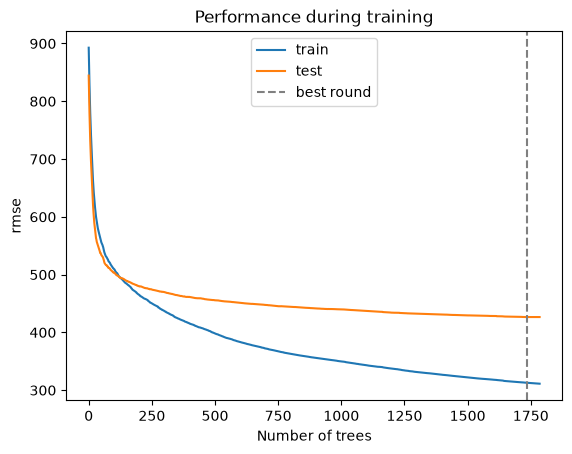

In [10]:
evals_result = model.get_evals_result()

plt.plot(evals_result["learn"]["RMSE"], label="train")
plt.plot(evals_result["validation"]["RMSE"], label="test")
plt.axvline(model.get_best_iteration(), color="grey", linestyle="dashed", label="best round")
plt.xlabel("Number of trees")
plt.ylabel("rmse")
plt.title("Performance during training")
plt.legend()
plt.show()

The test rmse reached its lowest value with 1736 trees, and early stopping trained 50 more rounds before it gave up. CatBoost drops those extra rounds and returns a model with 1736 trees, because `use_best_model` is on by default when we pass an eval set.

In [11]:
def evaluate(model, train_pool, y_train, test_pool, y_test):
    for name, data, y in [("train", train_pool, y_train), ("test", test_pool, y_test)]:
        predictions = model.predict(data)
        rmse = root_mean_squared_error(y, predictions)
        r2 = r2_score(y, predictions)
        print(f"{name} rmse: {rmse:.2f}, r2: {r2:.4f}")


evaluate(model, train_pool, y_train, test_pool, y_test)

train rmse: 323.69, r2: 0.8756
test rmse: 426.49, r2: 0.7594


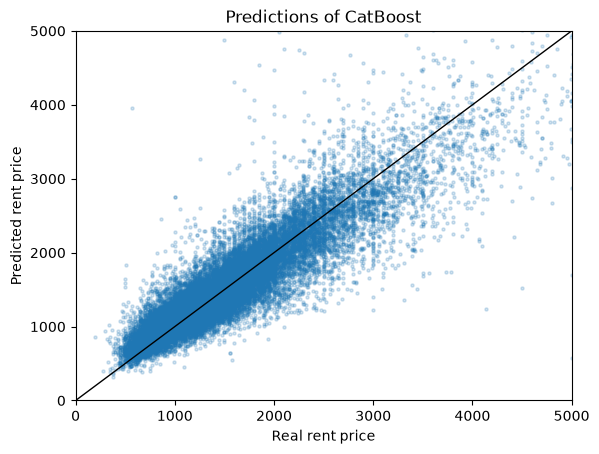

In [12]:
# Let's plot the predictions vs the true rent
# We zoom into the most common prices, because a few apartments cost more than 30000
predictions = model.predict(test_pool)

plt.scatter(y_test, predictions, alpha=0.2, s=5)
plt.plot([0, 5000], [0, 5000], color="black", linewidth=1)
plt.xlim(0, 5000)
plt.ylim(0, 5000)
plt.xlabel("Real rent price")
plt.ylabel("Predicted rent price")
plt.title("Predictions of CatBoost")
plt.show()

The model fits the train set better than the test set, with an rmse of 324 against 426, and its test error is much lower than the 522 of the gradient boosting machine with the default parameters in the previous section.

`get_all_params()` returns every parameter of the trained model, including the ones that CatBoost chose by itself.

In [13]:
all_params = model.get_all_params()

pd.Series({name: all_params[name] for name in ["learning_rate", "boosting_type", "bootstrap_type", "subsample"]})

learning_rate     0.064986
boosting_type        Plain
bootstrap_type         MVS
subsample              0.8
dtype: object

With 2000 rounds, 69872 rows and an eval set, CatBoost chose a learning rate of about 0.065.

Let's now change one hyperparameter at a time to understand what is going on.

CatBoost chooses the learning rate from the number of rounds, the number of rows and whether there is an eval set, so we fix the one that it chose for the default model.

In [14]:
fixed_params = {**params, "learning_rate": all_params["learning_rate"]}


def timed_train(params, pool, num_rounds):
    start = time.perf_counter()
    model = cb.CatBoostRegressor(**params, iterations=num_rounds).fit(pool, verbose=False)
    return model, time.perf_counter() - start

In [15]:
def scores(model, train_pool, y_train, test_pool, y_test):
    predictions = model.predict(test_pool)
    return {
        "train rmse": root_mean_squared_error(y_train, model.predict(train_pool)),
        "test rmse": root_mean_squared_error(y_test, predictions),
        "test r2": r2_score(y_test, predictions),
    }

### Ordered or plain boosting by depth

We saw in the lecture on prediction shift that plain boosting computes the gradient of each row with a model that has already seen that row, and in the lecture on ordered boosting that CatBoost avoids this by taking each gradient from a model fitted on earlier rows only. A deeper tree fits the rows that it was trained on more closely, so the prediction shift of plain boosting should grow with the depth. Ordered boosting does more work for each tree, so we compare the two boosting types with a `depth` from 2 to 10, on the test score and on the time.

The depth changes how many trees the model needs, so here every setting trains 2000 rounds with the test set as eval set, and CatBoost keeps the best round, as it did for the default model. We do not stop early, so that every setting trains the same rounds. The times depend on the machine, so we should read them relative to each other.

In [16]:
results = {}
for depth in [2, 4, 6, 8, 10]:
    for boosting_type in ["Plain", "Ordered"]:
        start = time.perf_counter()
        fitted = cb.CatBoostRegressor(**{**fixed_params, "depth": depth, "boosting_type": boosting_type}, iterations=2000).fit(
            train_pool, eval_set=test_pool, verbose=False
        )
        seconds = time.perf_counter() - start
        results[(depth, boosting_type)] = {
            "trees": fitted.tree_count_,
            "seconds": seconds,
            **scores(fitted, train_pool, y_train, test_pool, y_test),
        }

depth_results = pd.DataFrame(results).T.astype({"trees": int})
depth_results.index.names = ["depth", "boosting"]
depth_results.round(4)

trees   seconds  train rmse  test rmse  test r2
depth boosting                                                 
2     Plain      1998   49.8176    470.8606   498.7321   0.6710
      Ordered    1970   74.4839    506.3566   519.0021   0.6438
4     Plain      1987   99.1827    376.9176   443.9946   0.7393
      Ordered    2000  126.2426    437.8506   480.4054   0.6948
6     Plain      1998  158.9869    316.3696   424.3955   0.7618
      Ordered    1996  249.2651    410.1100   467.7543   0.7106
8     Plain      1998  229.7309    276.8170   403.5545   0.7846
      Ordered    1992  416.3005    382.3952   445.6341   0.7374
10    Plain      2000  341.8924    240.9245   391.1138   0.7977
      Ordered    1906  862.4773    359.0504   436.5138   0.7480

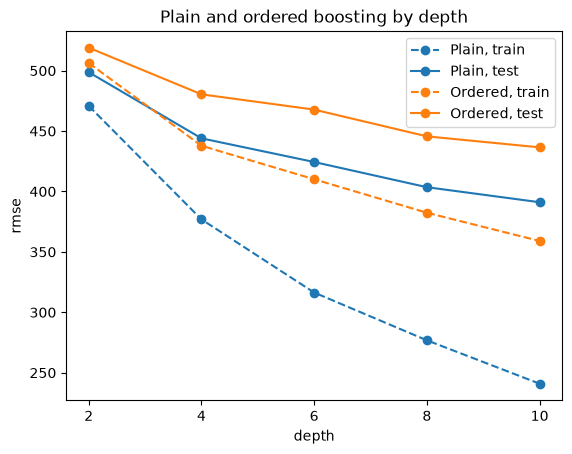

In [17]:
for boosting_type, color in [("Plain", "C0"), ("Ordered", "C1")]:
    rows = depth_results.xs(boosting_type, level="boosting")
    plt.plot(rows.index, rows["train rmse"], marker="o", color=color, linestyle="dashed", label=f"{boosting_type}, train")
    plt.plot(rows.index, rows["test rmse"], marker="o", color=color, label=f"{boosting_type}, test")
plt.xticks([2, 4, 6, 8, 10])
plt.xlabel("depth")
plt.ylabel("rmse")
plt.title("Plain and ordered boosting by depth")
plt.legend()
plt.show()

At the default depth of 6, ordered boosting raises the test rmse from 424 to 468, and it is slower at every depth. Both types improve with every level, plain boosting from 499 to 391 and ordered boosting from 519 to 437, so on this data ordered boosting only costs accuracy and time. Every setting has its best round within the last 100 of the 2000 trees, so all of them might still improve with more trees.

### Bootstrap type

We saw in the lectures on hyperparameters that MVS, the default `bootstrap_type`, keeps the rows with the largest gradients and samples the rest, Bernoulli keeps each row with the same chance, and the Bayesian bootstrap drops no row and gives each row a random weight, which grows more uneven as `bagging_temperature` rises. We compare no sampling, Bernoulli and MVS with their default `subsample`, and the Bayesian bootstrap at a temperature of 1 and 5. Every setting trains the number of trees that early stopping found, so that differences in time come from the setting and not from the number of trees.

In [18]:
# CatBoost rejects subsample with No and Bayesian, and bagging_temperature with No
bootstrap_params = {
    name: value for name, value in fixed_params.items() if name not in ["subsample", "bagging_temperature"]
}
bootstrap_settings = {
    "No": {"bootstrap_type": "No"},
    "Bernoulli, subsample 0.66": {"bootstrap_type": "Bernoulli", "subsample": 0.66},
    "MVS, subsample 0.8": {"bootstrap_type": "MVS", "subsample": 0.8},
    "Bayesian, temperature 1": {"bootstrap_type": "Bayesian", "bagging_temperature": 1},
    "Bayesian, temperature 5": {"bootstrap_type": "Bayesian", "bagging_temperature": 5},
}

In [19]:
results = {}
for name, setting in bootstrap_settings.items():
    fitted, seconds = timed_train({**bootstrap_params, **setting}, train_pool, num_rounds)
    results[name] = {"seconds": seconds, **scores(fitted, train_pool, y_train, test_pool, y_test)}

pd.DataFrame(results).T.round(4)

,seconds,train rmse,test rmse,test r2
No,132.4171,325.5770,427.3115,0.7585
"Bernoulli, subsample 0.66",122.5693,326.6719,428.7987,0.7568
"MVS, subsample 0.8",128.0052,323.6871,426.4934,0.7594
"Bayesian, temperature 1",133.6378,324.2617,429.4340,0.7561
"Bayesian, temperature 5",135.5945,362.6039,447.4897,0.7352


With the same 1736 trees, MVS lowers the test rmse a little, from 427 without sampling to 426, while Bernoulli raises it to 429. The Bayesian bootstrap raises it to 429 with a temperature of 1 and to 448 with 5, as its weights grow more uneven. MVS, the default, gives the lowest test rmse, and the times in the table differ little, so we keep the default.

### Combinations of categorical variables

We saw in the lecture on feature combinations that CatBoost combines categorical variables greedily while it builds each tree, and computes target statistics on the combinations as well. `max_ctr_complexity` is the largest number of variables in one combination, so 1 means no combinations at all. We train with 1 to 4.

In [20]:
results = {}
for complexity in [1, 2, 3, 4]:
    fitted, seconds = timed_train({**fixed_params, "max_ctr_complexity": complexity}, train_pool, num_rounds)
    results[complexity] = {"seconds": seconds, **scores(fitted, train_pool, y_train, test_pool, y_test)}

pd.DataFrame(results).T.round(4)

,seconds,train rmse,test rmse,test r2
1,94.6727,311.6533,429.0814,0.7565
2,129.0102,326.9725,423.3074,0.7630
3,127.6696,326.5740,425.2317,0.7609
4,128.5086,323.6871,426.4934,0.7594


With the same 1736 trees, combining categorical variables barely changes the test rmse on this data: 429 without combinations, then 423, 425 and 426 with up to 2, 3 and 4 variables in a combination, with no clear direction. The model without combinations trains fastest.

## Feature importance

We saw in the lecture on feature importance that XGBoost summarizes the splits of each feature as weight, gain and cover. CatBoost's default type, `PredictionValuesChange`, also comes from the trees alone: for every split on a feature, it compares the leaves that differ only in that split and adds up the squared distances of their values from their weighted average, weighted by the number of training rows in each leaf. The features add up to 100. It is closest to a total gain, but it measures the change of the predictions, not of the loss.

CatBoost also offers `LossFunctionChange`, which measures on a dataset how much the loss grows without each feature, and types that explain single predictions, such as `ShapValues`; we do not use them here. We plot the 15 most important features.

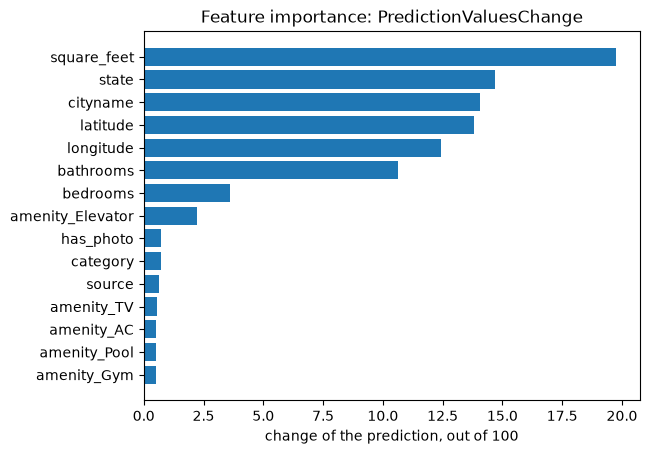

In [21]:
prediction_change = pd.Series(
    model.get_feature_importance(type="PredictionValuesChange"),
    index=model.feature_names_,
).sort_values(ascending=False)

# the 15 most important features, the most important on top
top = prediction_change.head(15)
plt.barh(top.index[::-1], top.values[::-1])
plt.xlabel("change of the prediction, out of 100")
plt.title("Feature importance: PredictionValuesChange")
plt.show()

By `PredictionValuesChange`, the size of the apartment and its location lead: `square_feet` comes first, followed by `state`, `cityname`, `latitude` and `longitude`, and then `bathrooms`. Together, these six features hold about 85 of the 100 points.